# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.

**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [1]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cpu | torch 2.14.1+cpu


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

Voy a trabajar exlcusivamente con CPU, por que en los tps anteriores mi INTEL arc 140V me estaba trayendo problemas con los datos y con pytorch.

In [2]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 5s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


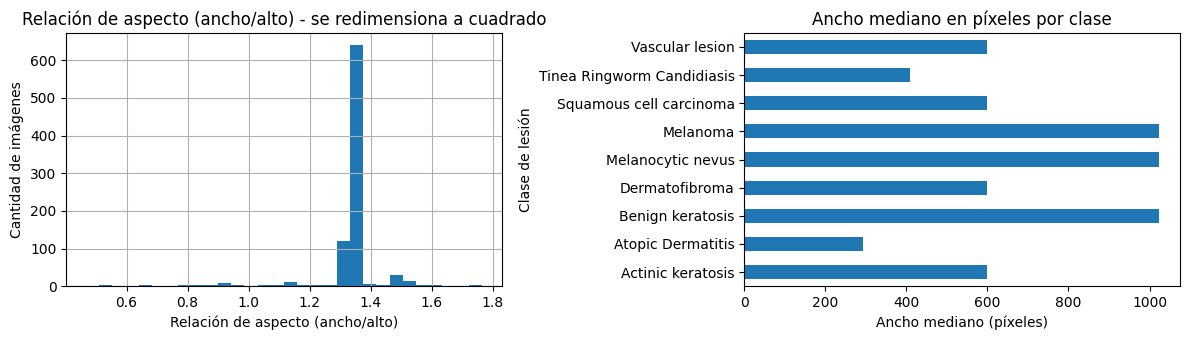

In [17]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase")
# set_xlabel y set_ylabel identifican la variable y la frecuencia del histograma.
ax[0].set_xlabel("Relación de aspecto (ancho/alto)"); ax[0].set_ylabel("Cantidad de imágenes")
# set_xlabel y set_ylabel identifican la medida en píxeles y las clases del gráfico de barras.
ax[1].set_xlabel("Ancho mediano (píxeles)"); ax[1].set_ylabel("Clase de lesión")
plt.tight_layout(); plt.show()

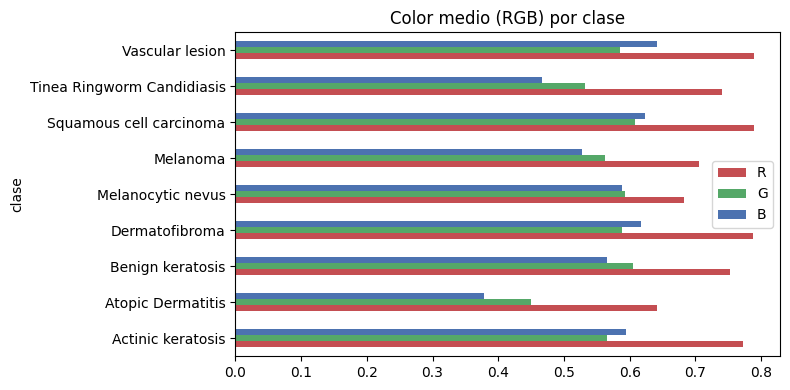

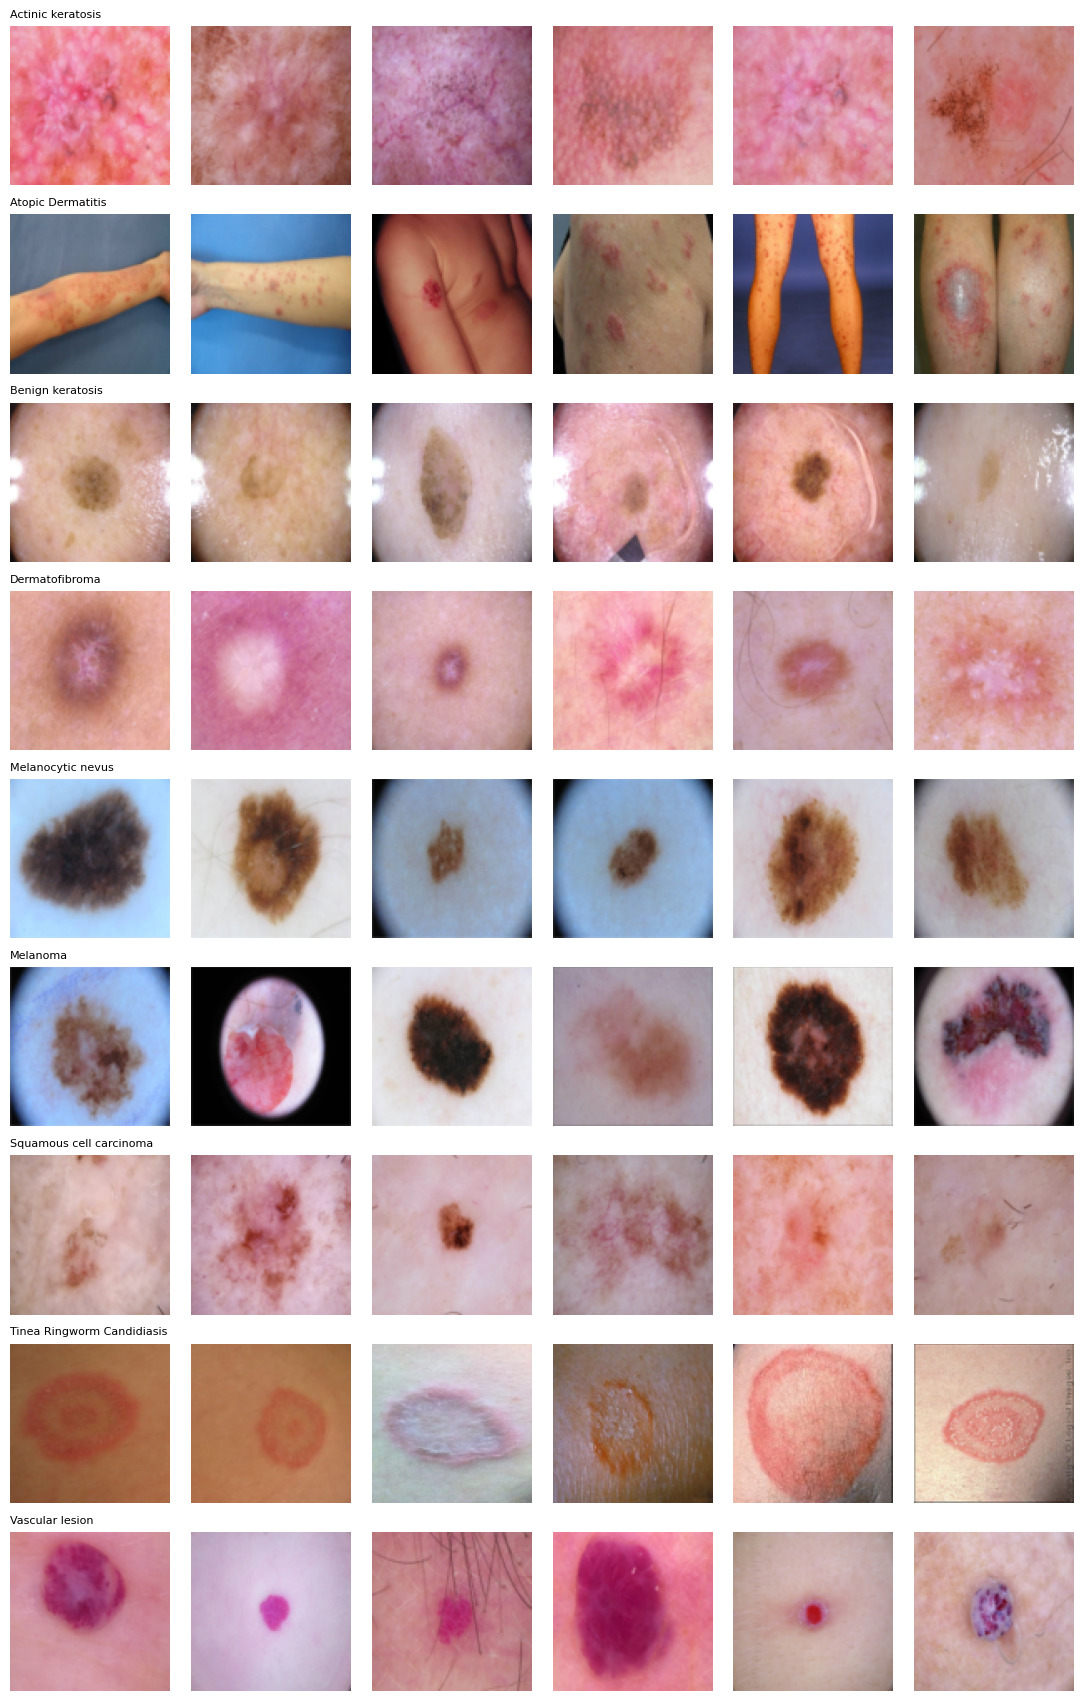

In [4]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [5]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
    1) antes del preprocesamiento, todas salvo una clase tienen aproximadamente 80 en train, y 20 en val. La ecepción es tinea Ringworm candiasis que tiene (56,20). Luego del preprocesamiento tienen incluso menos, ya que 12 estaban repetidas.
    Lo mismo ocurre para Atopic dermatitis que pierde 22 muestras al ser repetidas. 
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
    Si hay clases que se distinguen por tener imagenes en una unica resolución, por ejemplo atopic dermatitis que tiene el 100% de su dataset en una única resolucion (294x222) (102 imagenes), y es la  única que tiene esa resolucion. Y la distribución de valores medios de colores también varia entre clases. Esto puede traer problemas a la hora de testear con datasets nuevos, o a la hora de utilizar el modelo, ya que este último tiene que aprender a reconocer patrones en las imagenes, y no los colores que uso ni la resolución. Por ejemplo si invierto o flipeo los pixeles, el patron es el mismo. Se ampliará en data augmentation.
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?
    En la pregunta 1) mencioné en que clases encontró los duplicados. El problema no es tanto si entreno 2 veces con la misma imagen, lo cual no es bueno, pero lo grave seria en usar dev o test una imagen de la cual aprendió, ya que predicirá su clase con un accuracy que no es representativo de como generaliza el modelo, dandonos un accuracy mentiroso.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [6]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica. Es por esto ultimo que quizas invertir los colores no se una buena idea, ya que el modelo debe reconocer patrones y colores.

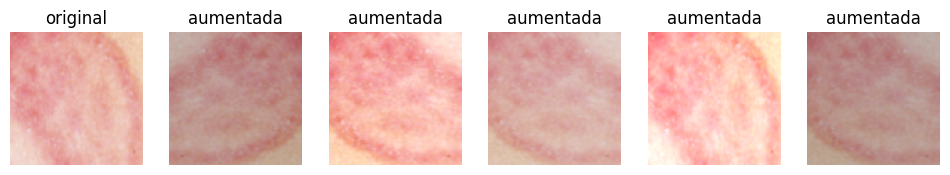

In [7]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [20]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),#capa 1
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))#capa 2
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


-CNN (64×64, 9 clases): P = 3²×(3×16 + 16×32 + 32×64) + 2×(16 + 32 + 64) + (64×8² + 1)×128 + (128 + 1)×9 = 549273 parámetros; 8 = 64/2³.

-MLP (64×64, 9 clases): P = (3×64² + 1)×512 + (512 + 1)×128 + (128 + 1)×9 = 6358793 parámetros.

-Campo receptivo de la última convolución: r = 1 + (3−1)×1 + (2−1)×1 + (3−1)×2 + (2−1)×2 + (3−1)×4 = 18 píxeles por lado.
Campo receptivo después del último pooling: r = 18 + (2−1)×4 = 22 píxeles por lado.

### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [21]:
# Inspecciona las capas del modelo con una imagen ficticia, sin entrenarlo.
# size es la longitud de cada lado en píxeles: se supone una entrada cuadrada.
def trace(model, size):
    # Activa evaluación (Dropout desactivado y BatchNorm con estadísticas almacenadas).
    # Crea un tensor de ceros: (1 imagen, 3 canales RGB, alto=size, ancho=size), y una lista de filas.
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    # Recorre primero las capas de features y luego las de head; i es el índice y l la capa.
    for i, l in enumerate(list(model.features) + list(model.head)):
        # Aplica la capa a x y registra índice, tipo, descripción completa,
        # forma de salida sin la dimensión del lote y cantidad de parámetros (pesos, sesgos, etc.).
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l), salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    # Devuelve la información de todas las capas como una tabla.
    return pd.DataFrame(rows)
# Crea una CNN nueva para entradas de 64x64, muestra la tabla y suma los parámetros.
tr = trace(CNN(64), 64)
# Evita que pandas recorte el contenido de las columnas al mostrar esta tabla.
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(tr)
print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
     Hacer padding = Kernel (3) / 2 es lo mismo que hacer pading = 'same', que mantiene el tamaño de la imagen, en este caso 64 (ancho y largo).
     Si pusiesemos pading =0, el tamaño seria 64-3+1 = 62.
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
El max pooling, toma la acticación maxima de un "pool" de kernel 2x2, al no colocar el stride, por defecto toma S=K,en nuestro caso 2.  
    Cada maxpooling divide a la mitad el tamaño, por lo tanto al aplicar varios bloques de MaxPooling(2)  reduces 2^n veces el tamaño. 64->32->16->8.
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
Modifiqúe el codigo con ia para aumentar la cantidad de caracteres en el detalle. 
De la capa 4 (conv2d) el numero de tamaño parametros es Canales_out*(canales_in * k^2 + 1 (bias)). En nuestro caso es 32 * (16 * 3^2 + 0) = 4608.
En la capa 12 (flatten), no tiene parametros por que no aprende, es simplemente un operador que transforma los tensores densos en un vector, para poder operarlo como MLP.
Por otro lado, linear es solo una capa de 128 unidades,cada neurona tiene un bias,  la salida es simplemente 4096*128 + 128.

4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm? Mi interpretación es que al sumarle sesgo, es como hacerle una transformación afín, al normalizar, este se cancela, por lo que es computacionalmente ineficiente calcular el bias para luego eliminarlo. 
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad? 
    b es cada capa convolucional. Las cuales tienen 16 filtros.
    la evolucion de canales es 3-> 16 *2^0-> 16*2^1-> 16*2^2 = 64.
    Se reduce la resolucion ya que estamos haciendo etapas de MaxPooling intermedias, a pesar de estar usando padding = same.
    Según me explico Codex, esto sirve para aumentar la variedad de caracteristicas, manteniendo una dimensionalidad razonable.

6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.
    No lo vimos en clase, le pedí ayuda a codex.
    r de la imagen original 1 r=j
    luego de la primera convolucion 1+ (3-1)*1 = 3, el 3 viene del kernel
    primer pooling 3+ (2-1)*1*1
    Seunda convolucion 4+(2-1)*1*2
    segundo pooling    8+ (2-1)*1*2
    tercera convolución 10+(3-1)*2*2.

    Son 2 sucesiones acopladas.
    r' = r+(kernel-1)*j
    j' = j*S.

    La interpretación es que cada posición del mapa “mira” una región de 18×18 píxeles. Su activación puede responder a una característica dentro de esa región, como un borde o una textura de la lesión.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 7 | val_acc 0.592 | train_acc 0.674 | 0.32 s/época | total 8s


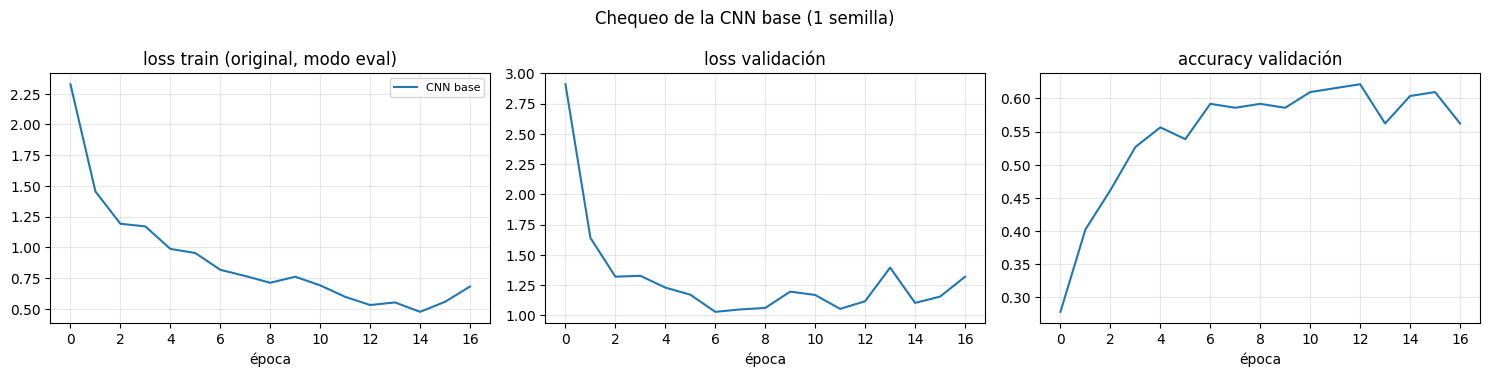

In [22]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion,DeltaPorcentual
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.0595,0.4346,0.0605,12.2178
1,MLP 64px,6358793,0.5030,0.0097,0.6509,0.1479,5.0000,0.1772,0.4661,0.0368,7.3203
2,CNN 32px,156057,0.6469,0.0195,0.8531,0.2062,10.3333,0.1140,0.5871,0.0598,9.2480
3,CNN 64px,549273,0.6410,0.0438,0.7787,0.1376,11.6667,0.4064,0.6055,0.0355,5.5385


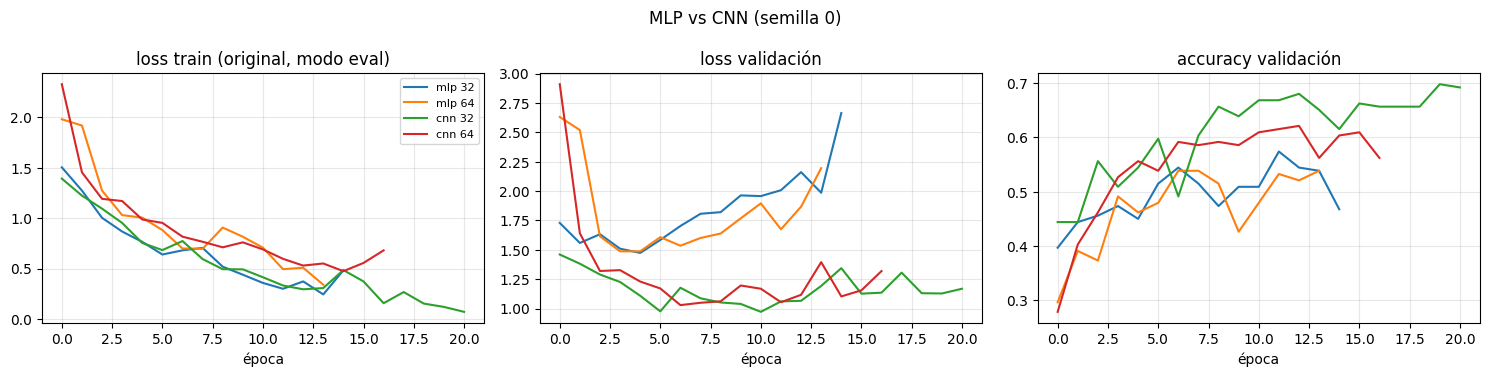

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [25]:
SHIFT = {32: 4, 64: 4}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
tabla_comparacion = pd.DataFrame(rows)
# Caída porcentual relativa respecto de val_acc; si vale cero, el porcentaje no está definido.
tabla_comparacion["DeltaPorcentual"] = (tabla_comparacion["val_acc"] - tabla_comparacion["val_acc_trasladada"]) / tabla_comparacion["val_acc"].replace(0, np.nan) * 100
display(tabla_comparacion.round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
Vamos a comparar entre la misma resolución:
-32px: diferencia = 0,1518, mayor que ambos desvíos: 0,0388 (MLP) y 0,0195 (CNN).
-64px: diferencia = 0,1380, mayor que ambos desvíos: 0,0097 (MLP) y 0,0438 (CNN).
Podemos coincidir que ambas CNN's tuvieron mejor desempeño que las MLPS en val_acc y tambien en train_acc. Esto se debe a que las CNN aprovechan la estructura espacial de las imágenes: detectan patrones locales y comparten filtros entre posiciones. Las MLP aplanan la imagen y no incorporan esas propiedades, por lo que necesitan aprenderlas a partir de los datos y utilizan muchos más parámetros.
MLP 32px: (3 × 32²) × 512 + 512 = 1.573.376 parámetros en la primera capa.
MLP 64px: (3 × 64²) × 512 + 512 = 6.291.968 parámetros en la primera capa.
MLP 224px: (3 × 224²) × 512 + 512 = 77.070.848 parámetros en la primera capa.

La CNN tiene menos parametros porque cada filtro se conecta solo con una region pequeña de la imagen, por ejemplo 3x3, y utiliza los mismos pesos al recorrerla. En cambio, en la MLP cada neurona de la primera capa se conecta con todos los pixeles. Por eso, al aumentar la resolucion, aumentan los parametros de esa capa de la MLP, mientras que los de la convolucion se mantienen iguales si no cambiamos los filtros, los canales y el kernel.

3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
Le pedi a codex que me agregue una entrada mas a la tabla que son las variaciones porcentuales al trasladerse. Me parece más representativo que la variación a secas.

En las redes convolucionales el procentaje es menor, ya que estan hechas para reconocer patrones a lo largo de la imagen y no una distribucion de pixeles.
En este caso se empeora mas al aumentar la resolución, cabe aclarar que tambien se aumento latrazlación de pixeles de 4 a 8. Por lo que en la última run veremos que pasa si la traslación es de 4 pixeles, al igual que en 32px.
Al reducir manualmente el corrimiento máximo de 8 a 4 pixeles en las imágenes de 64px, ambos modelos tuvieron una menor caída de accuracy. En la MLP, la val_acc trasladada pasó de 0,4214 a 0,4661 y la caída relativa bajó de aproximadamente 16,2% a 7,32%. En la CNN, la val_acc trasladada pasó de 0,5707 a 0,6055 y la caída relativa bajó de aproximadamente 11,0% a 5,54%.



4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?
La normalización ajusta la escala de los valores que recibe el modelo para facilitar un entrenamiento más estable. Primero se dividieron los pixeles por 255 para llevarlos al rango 0–1. Después se calcularon la media y el desvío de cada canal RGB usando solamente las imágenes de train, y se aplicó la fórmula (pixel − media) / desvío. Val y test se normalizaron con esas mismas estadísticas, evitando usar información de esos conjuntos para preparar el modelo.

Sin esta normalización, manteniendo el resto de la configuración, podríamos esperar una convergencia más lenta o menos estable y mayor sensibilidad a la tasa de aprendizaje. No significa que el modelo no pueda aprender ni que necesariamente tenga peor accuracy; habría que comprobarlo con un experimento.
Ayuda a mantener sensibilidades similares entre pesos.

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6410,0.0438,0.7787,0.1376,11.6667,0.7180,15.7674
1,2 bloques,8,1055001,0.6489,0.0329,0.8729,0.2239,15.0000,0.6754,16.8386
2,4 bloques,38,361113,0.6548,0.0218,0.8393,0.1844,16.3333,0.8539,22.3609
3,kernel 5,32,591001,0.6312,0.0322,0.8221,0.1910,18.3333,0.8096,22.8662
4,kernel 7,46,653593,0.6174,0.0074,0.7398,0.1224,15.3333,1.1185,28.3458
5,8 filtros,18,269521,0.6233,0.0388,0.7997,0.1765,8.6667,0.4239,7.8908
6,32 filtros,18,1143337,0.5838,0.0238,0.6983,0.1145,10.0000,1.2804,25.5919
7,32 px,18,156057,0.6469,0.0195,0.8531,0.2062,10.3333,0.2330,4.7326
8,96 px,18,1204633,0.5917,0.0302,0.7530,0.1612,12.3333,1.1869,26.5008


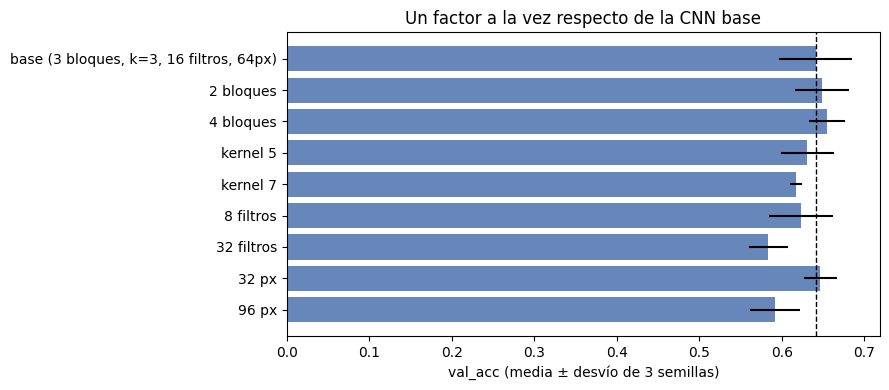

In [12]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.

“Kernel 7, 32 filtros y resolución de 96px reducen la accuracy media un 3,68%, 8,92% y 7,69%, respectivamente, respecto de la base. Aunque la caída con kernel 7 supera tres desvíos de esa variante, no supera el desvío de la base. Por eso, observamos caídas en las medias, pero no podemos afirmar que las tres superen claramente el ruido entre semillas.”


2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.

La base tiene un campo receptivo de 18px sobre una imagen de 64px. Con 4 bloques aumenta a 38px y con kernel 7, a 46px. Esperábamos que mirar regiones más grandes ayudara a combinar bordes y texturas y captar formas más generales de la lesión. Esto no significa que la base ignore el resto de la imagen, porque la capa Linear combina todos los mapas.

Al pasar de 3 a 4 bloques, la val_acc sube de 0,6410 a 0,6548, pero la diferencia es pequeña respecto del ruido. El tiempo por época aumenta de 0,718 a 0,854 segundos, aunque los parámetros bajan de 549273 a 361113: el pooling adicional reduce la entrada de la Linear.

Con kernel 7, la val_acc baja a 0,6174, los parámetros suben a 653593 y el tiempo por época a 1,119 segundos. En esta prueba, aumentar el kernel tuvo más costo sin mejorar la accuracy. Por lo tanto, un campo receptivo mayor no garantizó un mejor resultado.

Al poner mas capas con pooling, se achica la cantidad de parametros.
ntonces, la primera Linear pasa de:
- 4096 × 128 + 128 = 524416 parámetros.
- 2048 × 128 + 128 = 262272 parámetros. 
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
Todas las primeras capas linear tiene 128 neuronas por lo que el numero de parametros depende de la entrada canales (64) por ancho y  alto post pooling. 
- 32px: (64 × 4²) × 128 + 128 = 131200 parámetros.
- 64px: (64 × 8²) × 128 + 128 = 524416 parámetros.
- 96px: (64 × 12²) × 128 + 128 = 1179776 parámetros.
Al aumentar la resolución tenemos más detalle disponible, pero también más parámetros y mayor tiempo de cómputo. El campo receptivo sigue siendo de 18px por lado, que representa el 56,25% del lado de una imagen de 32px, el 28,13% de una de 64px y el 18,75% de una de 96px. Por lo tanto, cada posición de la última convolución mira una región proporcionalmente menor de la imagen.
Quizás tener mayor resolución ayude si tenemos más datos en train.
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?
Al cambiar un factor a la vez no podemos saber cómo interactúan entre sí, por ejemplo si aumentar el kernel funcionaría mejor junto con más bloques. Tampoco podemos afirmar que encontramos la mejor combinación posible.

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,brecha_porcentual,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6410,0.0438,0.7787,0.1376,17.6754,1.0169,11.6667,0.3655,8.3639
1,flips,1518,0.6016,0.0322,0.7833,0.1817,23.1964,1.0604,6.0000,1.0745,17.1529
2,flips+rot90,1518,0.6607,0.0195,0.8155,0.1548,18.9808,1.1018,10.3333,1.0262,20.8303
3,flips+rot90+color,1518,0.6371,0.0101,0.8307,0.1936,23.3078,1.0376,11.6667,1.1329,24.8361


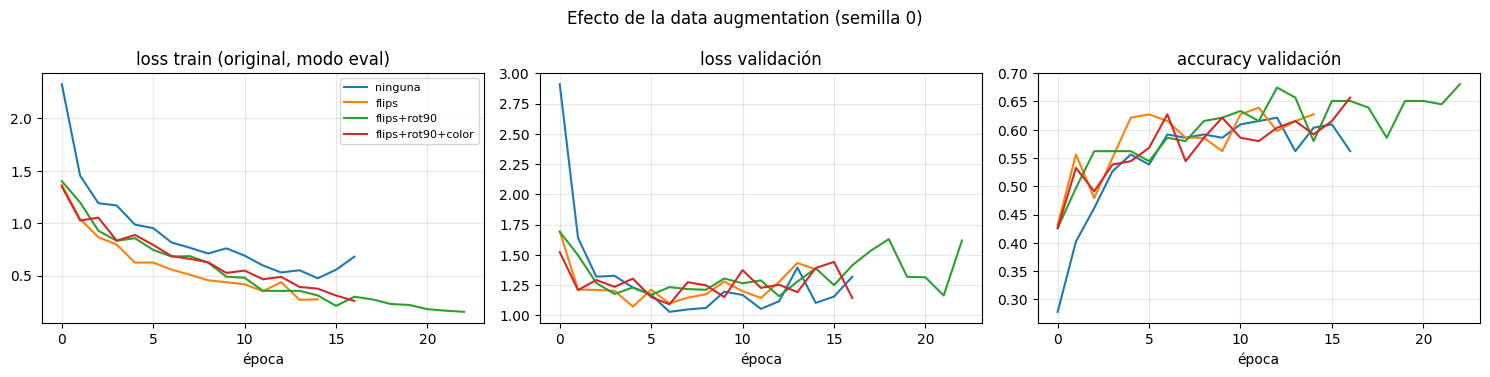

In [26]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
# Brecha relativa a train_acc, expresada en porcentaje; no definida si train_acc es cero.
tab_aug.insert(tab_aug.columns.get_loc("brecha") + 1, "brecha_porcentual", tab_aug["brecha"] / tab_aug["train_acc"].replace(0, np.nan) * 100)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "brecha_porcentual", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
Nuevamente agrgue brecha porcentual.
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
Sin augmentation, val acc queda 0.6410 y trainacc con 0.7787 con una brecha porcentual de 17.68% o de 0.1376 puntos, lo cual es una gran difencia. Podemos observar que a partir de la epoca 0 hasta la epoca 2, la losstrain disminuye medio punto, mientras que en el mismo intervalo la loss validacion cae 1.30 aprox, lo cual es bastante si las comparamos con las augmentations. (valores extraidos visualmente por mi).
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
La brecha no mejora lo suficiente como para decir es representativa, incluso hubo empeoramientos. Lo que si podemos observar es el efecto regularizador en realentizar el overfitting, esto se ve con una pendiente muchos menos empinada al comienzo, menor variación a lo largo del trial.
- Con data augmentation tenemos el triple de datos, por lo que naturalmente tardará más en recorrer todo el train. 
- La que mejor resultado tiene es flip+90 (acc_val=0.66)
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
- Con 0 conocimientos dermatologicos, puedo suponer que lo que importa para detectar una enfermedad u otra es el color, forma y tamaño, por lo que intuitivamente no modificaria estas caracteristicas. Si usaria flips, rotaciones, cambios en saturacion, y cambios en el angulo de captura de imagen (desde donde saco la foto) con RandomPerpective.
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
Es importante hacerlo despues del split, por que para testear necesitamos las imagenes reales diagnosticadas por un experto y otro estudios como sangre etc. Es por esto los datos de train y dev son "sagrados", y estos son escasos. Por lo que para obtener más muestras de manera económica, recurrimos a reciclar artificalmente el dataset de train.
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?
Data augmentation es una forma de regularización. En los tps anteriores,vos podrias haber regularizado de una forma similar si es que hubiesemos tenido acceso a más muestras. Para hacer dataaugmenation necesitas de cierta forma saber como se generan los datos. En el caso de las imagenes, flipear una imagen no afecta en nada su contendio, si a sus datos, es por esto que aquí si es valido crear artificialmente estas nuevas muestras ya que son pequeñas variaciones de la misma información, y no información nueva. 
Es un tipo de regularizacion distinto, ya que no castiga directamente a la loss, sino que modifica el train aumentando muestras.  

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [14]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 4 bloques | mejor augmentation (val): flips+rot90
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 4, 'filters': 16, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90'}
Config final en validación: val_acc 0.645 ± 0.013 | brecha 0.101 | mejor época 6.7 | 35s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,361113,0.6556,0.0325,0.646,0.0353,44.5061
1,MLP 64px,6358793,0.5006,0.0473,0.479,0.0489,4.1146


Error estándar binomial del test (169 imágenes): ±0.037 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.55      0.55      0.55        20
         Atopic Dermatitis       0.67      0.62      0.65        16
          Benign keratosis       0.90      0.90      0.90        20
            Dermatofibroma       0.45      0.70      0.55        20
         Melanocytic nevus       0.79      0.75      0.77        20
                  Melanoma       0.64      0.45      0.53        20
   Squamous cell carcinoma       0.45      0.45      0.45        20
Tinea Ringworm Candidiasis       0.38      0.38      0.38        13
           Vascular lesion       1.00      0.85      0.92        20

                  accuracy                           0.64       169
                 macro avg       0.65      0.63      0.63       169
              weighted avg       0.66      0.64      0.64       169



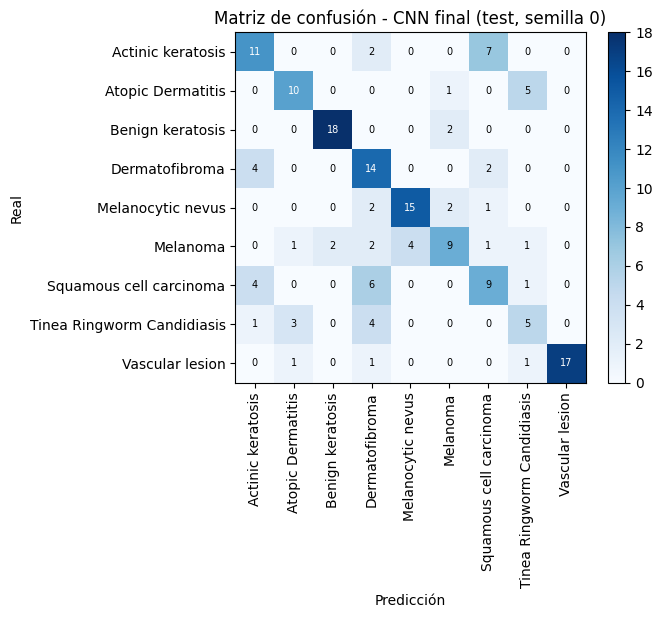

In [15]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

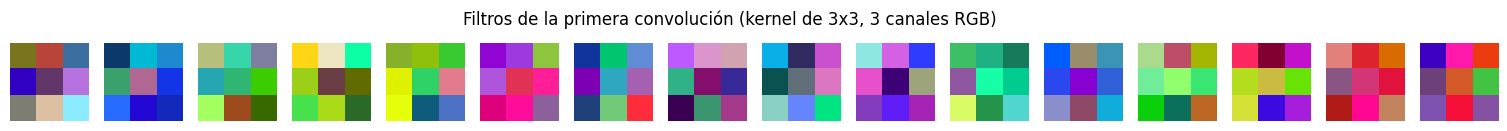

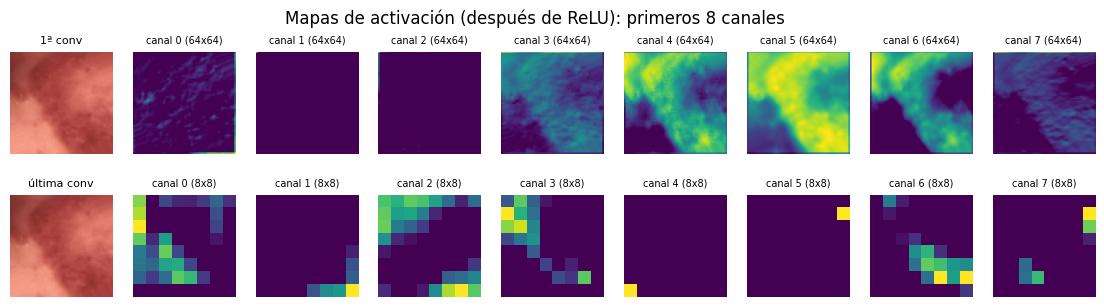

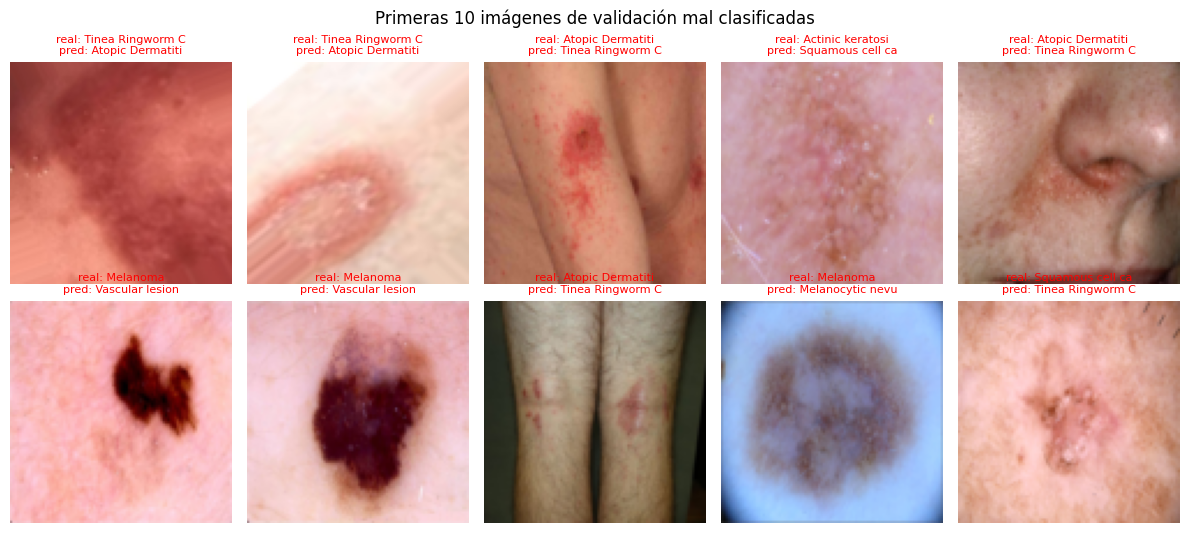

In [16]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
Config final en validación: val_acc 0.645 ± 0.013
test: 0.6556	
El resultado de test es coherente con validación: la CNN final obtuvo una val_acc de 0,645 y una test_acc de 0,6556. La diferencia es de aproximadamente 1,1 puntos porcentuales, menor que el error estándar del test, de 3,7 puntos, por lo que no indica una mejora clara. Además, como elegimos la configuración usando validación, ese resultado puede tener un sesgo optimista. Que test haya dado ligeramente mejor no contradice esto: también hay variabilidad por las pocas imágenes evaluadas.

2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
En mi opinión, el costo computacional se justifica, porque la mejora de 15,5 puntos porcentuales es considerable y el tiempo adicional de entrenamiento es de unos 40 segundos. Sin embargo, estos tiempos no permiten evaluar el costo de usar el modelo para predecir imágenes nuevas.

 Hay que contemplar que para la CNN se hizo data agumentation, triplicando el train, lo que obviamente se traduce en mas tiempo de entrenamiento. Cabe aclarar que el entrenamiento por parametro fue de 647ns/parametro en mlp, y de 123µs en CNN.
Aunque la CNN tiene menos parámetros, realiza más operaciones por imagen y entrena con tres veces más ejemplos por época debido a la augmentation. Ambas arquitecturas permiten paralelizar cálculos, pero estos resultados en CPU no permiten determinar cuál aprovecha mejor la paralelización ni cuánto acelerarían en GPU

3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
En la matriz de la semilla 0, las mayores confusiones son Actinic keratosis con Squamous cell carcinoma (7 imágenes), Squamous cell carcinoma con Dermatofibroma (6) y Atopic Dermatitis con Tinea (5). También se clasificaron 4 melanomas como Melanocytic nevus. Una posible explicación es que compartan colores, bordes o texturas parecidas, pero la matriz por sí sola no demuestra la causa.
Me preocupa el recall de melanomas, que solo pudo reconocer 9 de 20.
Supongo que importa que enfermedad detecta y cuales no, ya que hay enfermedades más graves que otras, y quizás en la practiva sea útil forzar un bias a predecir enfermedades más graves para dar más atención. Quizás esto no tenga sentido.

4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
4. En las primeras capas se detectan patrones locales, como cambios de color, bordes y texturas. En los mapas de 64x64 todavía se reconoce parte de la forma de la lesión; algunos canales resaltan detalles y otros casi no se activan. En la última convolución los mapas son de 8x8 y las activaciones están más concentradas: se pierde detalle espacial y se combinan características de regiones más grandes. Estos mapas se muestran antes del último pooling.
Entre las imágenes mal clasificadas se repiten lesiones rojizas y con texturas parecidas.
También varias de las imagenes son tomadas desde lejos, lo que permite ver otras partes del cuerpo como nariz, piernas o pelos etc. 

5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?
    Hay que contemplar que las clases tienen diferencias de resolución y color. Por ejemplo, todas las imágenes de Atopic Dermatitis son de 294x222. El modelo podría aprender características de cómo se sacó la foto y asociarlas con una clase, en lugar de aprender solamente sobre la lesión. Aunque redimensionemos las imágenes, no necesariamente eliminamos estas diferencias.
También había 34 grupos de duplicados, 33 compartidos entre train y val, que hubiesen inflado los resultados si no se eliminaban. Después de la limpieza quedaron solo 506 imágenes de train y 169 de val y test respectivamente. En mi opinión, con más tiempo buscaría más imágenes de distintas fuentes y comprobaría que no haya fotos del mismo paciente en diferentes conjuntos. También probaría más semillas y validación cruzada, porque una sola partición y tan pocas imágenes no alcanzan para asegurar que estos resultados se mantengan con datos nuevos.

## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

>Utilizo chatGPT integrado a VSC. Lo utilizo para consultas teóricas, explicar código y escribir en celdas.
    Celda # 1.1 Clases y carpeta de origen: Puse labels en los ejes
    A lo largo de varias celdas fui poniendo para que las fui usando. 
    